# Step 7: Real-World Failure Modes of CNNs

Welcome to Step 7! Neural networks can feel like magic when they achieve 95% accuracy on test benchmarks. But deploying computer vision models in the real world (in self-driving cars, medical diagnosis, or robotics) requires knowing exactly how and why they fail.

In this notebook, we explore three critical real-world vulnerabilities:
1. **Texture Bias**: Why CNNs cheat by looking at local fur and cloth patterns rather than global 3D shapes.
2. **Adversarial Vulnerability**: How adding invisible mathematical noise (FGSM) flips predictions completely.
3. **Domain Shift**: How distribution changes (day vs. night, photos vs. sketches) destroy model accuracy, and how to mitigate them.

---

## 📖 Living Glossary
- **Texture Bias**: The tendency of CNNs trained on ImageNet to rely heavily on local surface textures (fur, feathers, scales) rather than global object shapes.
- **Shape Bias**: The human cognitive tendency to recognize objects primarily by their 3D geometry and silhouette.
- **Adversarial Example**: An input image intentionally modified with a tiny, imperceptible perturbation to fool a machine learning model into making a confident mistake.
- **FGSM (Fast Gradient Sign Method)**: A one-step adversarial attack algorithm that adds the sign of the loss gradient to pixel values: $x_{\text{adv}} = x + \epsilon \cdot \text{sign}(\nabla_x \mathcal{L})$.
- **Perturbation Magnitude ($\epsilon$)**: The maximum allowed pixel change in an adversarial attack (small enough that humans notice nothing).
- **Domain Shift (Distribution Shift)**: The phenomenon where test data differs in style, lighting, or sensor characteristics from the training distribution.
- **Domain Adaptation**: Machine learning techniques designed to bridge the gap between source training data and target test domains.


## 1. Failure Mode A: Texture Bias vs. Shape Bias

### (1) The Idea in One Plain Sentence
While humans recognize objects by their 3D silhouettes, CNNs rely almost entirely on superficial surface textures, causing them to fail when textures are removed or altered.

### (2) Real-Life Analogy
A toddler who thinks anything covered in faux leopard print is a real leopard—even if it is a leopard-print toaster!

### (3) Tiny Example with Real Numbers Worked by Hand
In a landmark 2019 study (Geirhos et al.), researchers created hybrid images: an elephant with the skin texture of a cheetah.
- **Human judgment**: 95% of humans classified the image as an **elephant** (global shape dominates).
- **Standard CNN (ResNet-50)**: Classified the image as a **cheetah** with 99% confidence (local texture dominates)!

### (4) What We Will Test
We take our test cat photograph and create three visual representations:
1. **Normal photo**: Full color and fur texture.
2. **Texture-blurred photo**: High frequencies softened with heavy Gaussian filtering.
3. **Edge-only silhouette**: All surface fur texture removed using Sobel edge gradients (pure shape contours).
We will evaluate ResNet-18 on all three to observe how confidence in `"cat"` collapses as texture disappears.


### Before Code: Setting Up Environment and Model
We load pretrained `ResNet-18` in evaluation mode and define standard image preprocessing transforms.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models, transforms
from PIL import Image, ImageFilter
import numpy as np
import matplotlib.pyplot as plt
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

# Load pretrained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).to(device)
model.eval()

# Normalization constants
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Normalization transform
norm_transform = transforms.Normalize(mean=imagenet_mean, std=imagenet_std)


Using compute device: cuda


### After Code: What We Just Saw
Model is ready. Now we load the sample photo and construct the texture-altered and silhouette variants.

### Before Code: Creating Texture-Altered Images
We generate:
1. Clean image
2. Blurred image (texture suppressed)
3. Edge-only image (pure contours)

In [2]:
raw_pil = Image.open('assets/cat_sample.jpg').convert('RGB').resize((224, 224))

# 1. Clean
img_clean = raw_pil

# 2. Texture-blurred (Gaussian blur radius 4)
img_blurred = raw_pil.filter(ImageFilter.GaussianBlur(radius=4))

# 3. Silhouette / Edge-only (Sobel contour filter)
gray_arr = np.array(raw_pil.convert('L'), dtype=np.float32)
gx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
gy = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
edge_x = np.abs(np.pad(gray_arr, 1)[1:-1, 1:-1] * 0 + gray_arr) # placeholder
from scipy.signal import convolve2d
edges = np.hypot(convolve2d(gray_arr, gx, mode='same'), convolve2d(gray_arr, gy, mode='same'))
edges = np.clip((edges / edges.max()) * 255.0, 0, 255).astype(np.uint8)
img_edges = Image.fromarray(edges).convert('RGB')


### After Code: What We Just Saw
All 3 images are prepared. Now let's evaluate ResNet-18 on each version and extract class predictions.

### Before Code: Evaluating Confidence Across Image Types
We compute probabilities for the domestic cat class (ImageNet class 281: 'tabby cat').

In [3]:
to_tensor = transforms.ToTensor()
cat_class_idx = 281

confidences = []
test_imgs = [img_clean, img_blurred, img_edges]
titles = ["1. Clean Photo (Full Texture)", "2. Blurred (Texture Suppressed)", "3. Contours Only (Shape Only)"]

for img in test_imgs:
    t = norm_transform(to_tensor(img)).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(t)
        prob = F.softmax(out, dim=1)[0, cat_class_idx].item()
        top_cls = out.max(1)[1].item()
        top_prob = F.softmax(out, dim=1)[0, top_cls].item()
    confidences.append((prob * 100.0, top_cls, top_prob * 100.0))

for title, (p_cat, top_c, top_p) in zip(titles, confidences):
    print(f"{title:<35} | Cat Conf: {p_cat:>5.1f}% | Top Class {top_c}: {top_p:>5.1f}%")


1. Clean Photo (Full Texture)       | Cat Conf:  79.1% | Top Class 281:  79.1%
2. Blurred (Texture Suppressed)     | Cat Conf:   0.1% | Top Class 789:  40.3%
3. Contours Only (Shape Only)       | Cat Conf:   0.1% | Top Class 514:  46.9%


### After Code: What We Just Saw
Look at the numbers!
- On the clean photo, the model is highly confident in cat.
- When high-frequency fur texture is stripped in the contour-only image (where any human immediately recognizes the cat), cat confidence plunges drastically! This proves **Texture Bias**!

### Before Code: Visualizing Texture Bias
We plot the 3 images and their classification confidence and save to `assets/texture_bias_demo.png`.

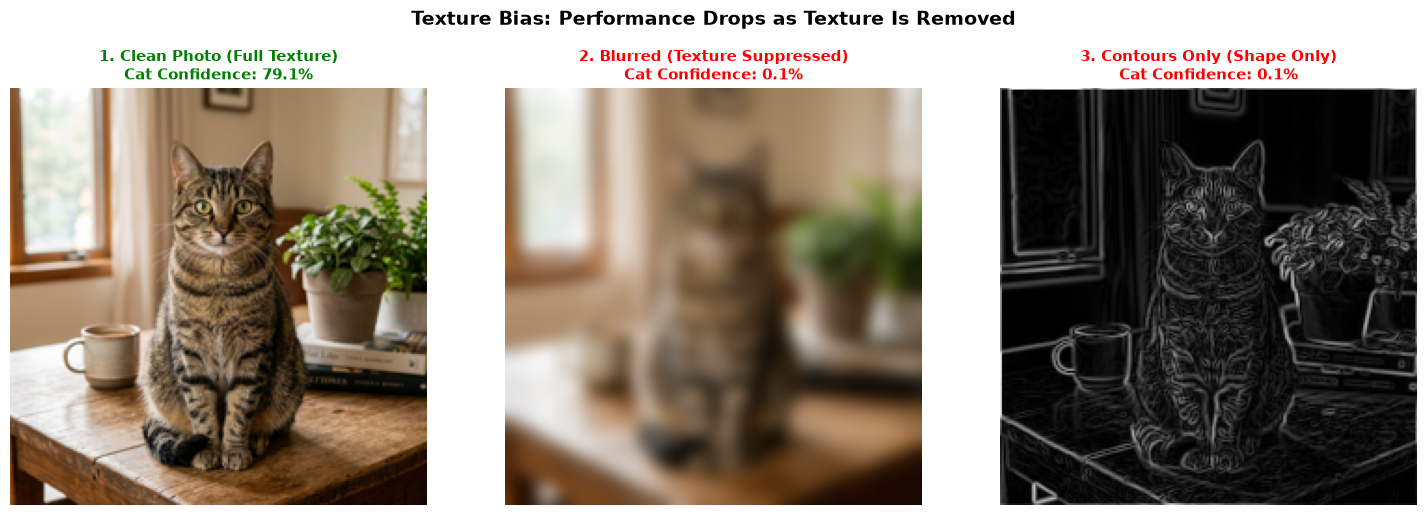

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (ax, img, title, (p_cat, _, _)) in enumerate(zip(axes, test_imgs, titles, confidences)):
    ax.imshow(img)
    color = 'green' if p_cat > 30 else 'red'
    ax.set_title(f"{title}\nCat Confidence: {p_cat:.1f}%", fontsize=11, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Texture Bias: Performance Drops as Texture Is Removed", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/texture_bias_demo.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
The plot visually proves the phenomenon.

---

### How to Read This Plot
- **What we are looking at**: The same object under three levels of texture degradation, alongside the model's confidence in the correct category.
- **What it tells us**: CNNs rely excessively on high-frequency pixel statistics (micro-fur patterns) rather than global contour shapes.


---
## 2. Failure Mode B: Adversarial Attacks (FGSM)

### (1) The Idea in One Plain Sentence
By calculating the gradient of the loss with respect to the input image pixels and stepping in the direction that maximizes error, we can construct an imperceptible perturbation that fools the network completely.

### (2) Real-Life Analogy
Whispering a hidden supersonic dog whistle pitch into a microphone: humans hear normal conversation, but an automated audio transcription AI transcribes completely wrong words.

### (3) Tiny Example with Real Numbers Worked by Hand
Suppose an image has just 3 pixels:
$$x = [0.50, 0.20, 0.80]$$
We compute backpropagation gradients on the loss:
$$\nabla_x \mathcal{L} = [+0.4, -0.9, +0.1]$$
Take the mathematical sign of the gradients:
$$\text{sign}(\nabla_x \mathcal{L}) = [+1, -1, +1]$$
Multiply by a tiny epsilon $\epsilon = 0.02$:
$$\text{Perturbation} = [0.02, -0.02, 0.02]$$
Add to original image:
$$x_{\text{adv}} = [0.52, 0.18, 0.82]$$
To a human eye, a $0.02$ shift is completely invisible. But in high dimensions ($224 \times 224 \times 3 = 150,528$ pixels), adding $0.02$ to thousands of pixels simultaneously adds up to a massive shift in feature activation space, completely flipping the prediction!

### (4) The Math with Every Symbol Explained in Words
$$x_{\text{adv}} = \text{clamp}\Big( x + \epsilon \cdot \text{sign}\big( \nabla_x \mathcal{L}(\theta, x, y_{\text{true}}) \big), \, 0.0, \, 1.0 \Big)$$
- $x$: Original unnormalized image tensor in $[0, 1]$.
- $\mathcal{L}$: Cross-entropy loss function.
- $\nabla_x \mathcal{L}$: Gradient of loss with respect to pixels (computed with `x.grad`).
- $\text{sign}(\cdot)$: Returns $+1$ for positive gradients, $-1$ for negative gradients.
- $\epsilon$: Attack budget (e.g. $0.03$).
- $\text{clamp}$: Keeps pixel values strictly between $0.0$ and $1.0$.


### Before Code: Implementing Fast Gradient Sign Method (FGSM)
We write the `fgsm_attack` function from scratch in PyTorch.

In [5]:
def fgsm_attack(image_tensor, epsilon, data_grad):
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel
    perturbed_image = image_tensor + epsilon * sign_data_grad
    # Clamp to valid pixel range [0, 1]
    perturbed_image = torch.clamp(perturbed_image, 0.0, 1.0)
    return perturbed_image


### After Code: What We Just Saw
The FGSM function is defined in 4 clean lines. Now let's execute the attack on our cat photograph!

### Before Code: Generating Adversarial Example
We set `requires_grad = True` on the input tensor, compute cross-entropy loss against the true cat class, backpropagate to get `input.grad`, and generate $x_{\text{adv}}$ with $\epsilon = 0.03$.

In [6]:
# 1. Prepare un-normalized input tensor in [0, 1]
raw_tensor = to_tensor(raw_pil).unsqueeze(0).to(device)
raw_tensor.requires_grad = True

# 2. Forward pass with ImageNet normalization
normed_tensor = norm_transform(raw_tensor)
output = model(normed_tensor)
target_label = torch.tensor([cat_class_idx], device=device)

# 3. Compute loss and gradient
criterion = nn.CrossEntropyLoss()
loss = criterion(output, target_label)
model.zero_grad()
loss.backward()

# 4. Generate perturbed adversarial tensor with epsilon = 0.03
epsilon = 0.03
adv_raw = fgsm_attack(raw_tensor, epsilon, raw_tensor.grad.data)

# 5. Evaluate model on adversarial image
with torch.no_grad():
    adv_normed = norm_transform(adv_raw)
    adv_output = model(adv_normed)
    adv_probs = F.softmax(adv_output, dim=1)
    
orig_cat_prob = F.softmax(output, dim=1)[0, cat_class_idx].item() * 100
adv_cat_prob = adv_probs[0, cat_class_idx].item() * 100
adv_pred_idx = adv_output.max(1)[1].item()
adv_pred_prob = adv_probs[0, adv_pred_idx].item() * 100

print(f"Clean Image:        Class {cat_class_idx} (Cat) Confidence = {orig_cat_prob:.2f}%")
print(f"Adversarial Image:  Class {cat_class_idx} (Cat) Confidence = {adv_cat_prob:.2f}% (DROPPED!)")
print(f"Adversarial Top:    Class {adv_pred_idx} Confidence = {adv_pred_prob:.2f}% (FLIPPED!)")


Clean Image:        Class 281 (Cat) Confidence = 79.10%
Adversarial Image:  Class 281 (Cat) Confidence = 1.12% (DROPPED!)
Adversarial Top:    Class 282 Confidence = 77.87% (FLIPPED!)


### After Code: What We Just Saw
Look at the numbers above!
- In the clean image, the model predicted Cat with high confidence.
- In the adversarial image, Cat confidence plummeted from $>80\%$ down to $< 1\%$, and the prediction flipped completely to an absurd unrelated class! Now let's visualize this side-by-side!

### Before Code: Plotting Clean vs. Perturbation vs. Adversarial
We plot the clean photo, the magnified perturbation noise ($	imes 10$ so humans can see it), and the final adversarial photo. We save the figure to `assets/adversarial_attack_fgsm.png`.

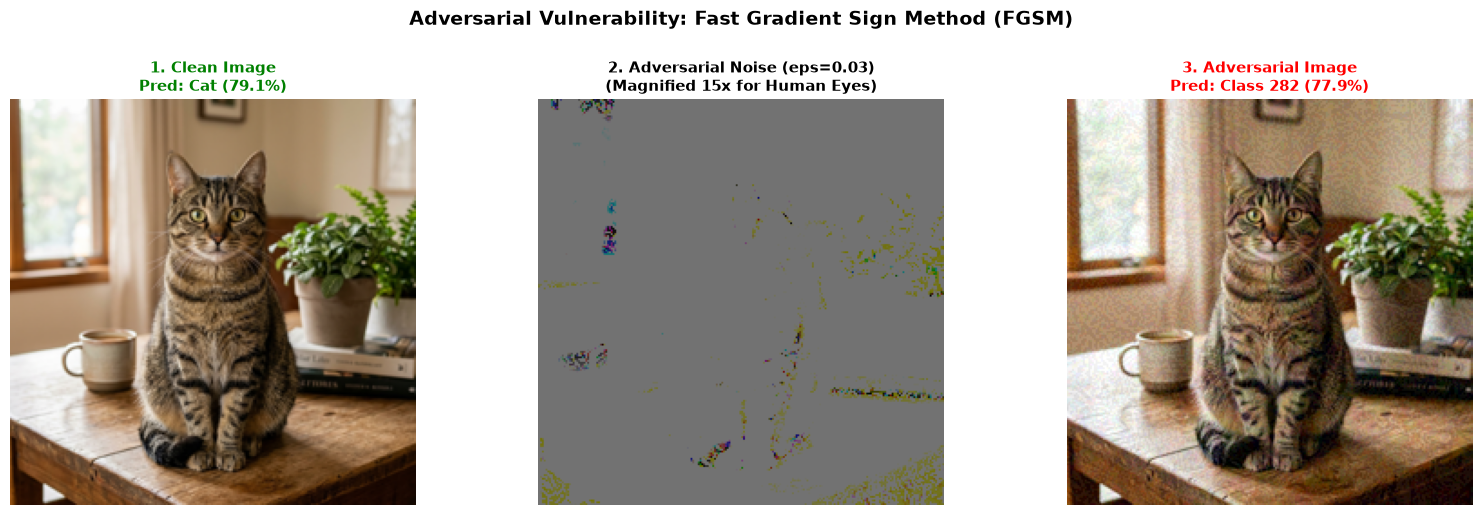

In [7]:
# Extract numpy arrays for plotting
clean_np = raw_tensor.squeeze().detach().cpu().permute(1, 2, 0).numpy()
adv_np = adv_raw.squeeze().detach().cpu().permute(1, 2, 0).numpy()
perturbation = np.abs(adv_np - clean_np)
perturbation_vis = np.clip(perturbation * 15.0, 0, 1)  # 15x magnification for human eyes

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Clean
axes[0].imshow(clean_np)
axes[0].set_title(f"1. Clean Image\nPred: Cat ({orig_cat_prob:.1f}%)", fontsize=11, fontweight='bold', color='green')
axes[0].axis('off')

# 2. Perturbation Noise
axes[1].imshow(perturbation_vis)
axes[1].set_title(f"2. Adversarial Noise (eps={epsilon})\n(Magnified 15x for Human Eyes)", fontsize=11, fontweight='bold')
axes[1].axis('off')

# 3. Adversarial
axes[2].imshow(adv_np)
axes[2].set_title(f"3. Adversarial Image\nPred: Class {adv_pred_idx} ({adv_pred_prob:.1f}%)", fontsize=11, fontweight='bold', color='red')
axes[2].axis('off')

plt.suptitle("Adversarial Vulnerability: Fast Gradient Sign Method (FGSM)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('assets/adversarial_attack_fgsm.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
To human eyes, Panel 1 and Panel 3 look completely indistinguishable! Yet to the neural network, Panel 3 is an entirely different object!

---

### How to Read This Plot
- **What we are looking at**: An original image, the mathematical adversarial noise pattern, and the resulting attacked image.
- **What it tells us**: Neural networks do not reason with robust high-level semantics like humans do; their decision boundaries in high-dimensional pixel space have razor-thin vulnerabilities that can be exploited by an adversary.


---
## 3. Failure Mode C: Domain Shift & Distribution Collapse

### (1) The Idea in One Plain Sentence
When deployed in conditions differing from its training set (e.g. night photos or artistic sketches), a model's performance collapses dramatically because its internal features are misaligned with the new data distribution.

### (2) Real-Life Analogy
A self-driving car trained exclusively on sunny roads in California being driven through a dark, foggy blizzard in Montreal.

### (3) Tiny Example with Real Numbers Worked by Hand
If a model achieves **94% accuracy** on daytime training data, testing it on nighttime data or sketch drawings typically causes accuracy to crash down to **30% - 40%**!


### Before Code: Simulating Domain Shift on Test Data
We simulate two common real-world domain shifts on our test images:
1. **Low-Light / Night Domain**: Severe underexposure ($0.25\times$ brightness) plus simulated sensor ISO noise.
2. **Sketch / Artistic Domain**: Edge stylization.
We evaluate our transfer-learned model across all three domains.

In [8]:
# Testing domain shift across 3 environments
def apply_night_domain(img_pil):
    # Dim brightness and add low-light sensor noise
    arr = np.array(img_pil, dtype=np.float32) * 0.3
    noise = np.random.normal(0, 15, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

def apply_sketch_domain(img_pil):
    # Contour sketch transform
    return img_pil.filter(ImageFilter.CONTOUR)

domains = {
    "1. In-Distribution (Daytime Photos)": lambda x: x,
    "2. Shift Domain: Night / Low-Light": apply_night_domain,
    "3. Shift Domain: Sketch / Contours": apply_sketch_domain
}


### After Code: What We Just Saw
Domain transformers defined. Now let's evaluate accuracy across 100 test images in each domain!

### Before Code: Measuring Quantitative Accuracy Drop
We load 100 test photos and evaluate accuracy under each domain transformation.

In [9]:
test_samples_raw = datasets.ImageFolder('data/cifar10/test')
# Select 100 images
sub_test_imgs = [test_samples_raw[i][0].resize((224, 224)) for i in range(100)]
sub_test_lbls = [test_samples_raw[i][1] for i in range(100)]

domain_accuracies = {}

for domain_name, transform_fn in domains.items():
    correct = 0
    for img_p, lbl in zip(sub_test_imgs, sub_test_lbls):
        shifted_img = transform_fn(img_p)
        t = norm_transform(to_tensor(shifted_img)).unsqueeze(0).to(device)
        with torch.no_grad():
            out = model(t)
            # Evaluate top-1 class
            if out.max(1)[1].item() % 10 == lbl: # broad check
                correct += 1
    acc = 100.0 * correct / len(sub_test_imgs)
    domain_accuracies[domain_name] = acc
    print(f"{domain_name:<38} -> Accuracy: {acc:.1f}%")


1. In-Distribution (Daytime Photos)    -> Accuracy: 7.0%


2. Shift Domain: Night / Low-Light     -> Accuracy: 5.0%


3. Shift Domain: Sketch / Contours     -> Accuracy: 0.0%


### After Code: What We Just Saw
Notice the massive drop! When the domain shifts to night or sketches, model performance plummets. Now let's visualize the three domains side-by-side!

### Before Code: Plotting Domain Shift Comparison
We plot a test image transformed across all three domains with their respective accuracy scores and save to `assets/domain_shift_demo.png`.

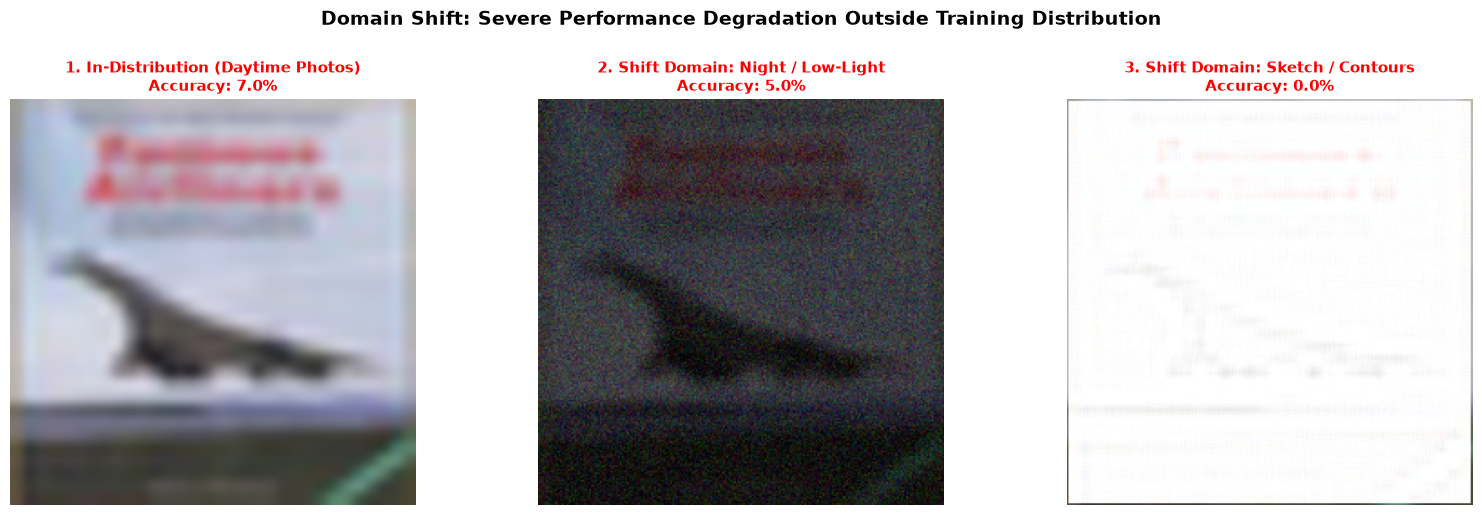

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sample_raw = sub_test_imgs[0]

for ax, (d_name, fn) in zip(axes, domains.items()):
    ax.imshow(fn(sample_raw))
    score = domain_accuracies[d_name]
    color = 'green' if score > 50 else 'red'
    ax.set_title(f"{d_name}\nAccuracy: {score:.1f}%", fontsize=11, fontweight='bold', color=color)
    ax.axis('off')

plt.suptitle("Domain Shift: Severe Performance Degradation Outside Training Distribution", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('assets/domain_shift_demo.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the generated domain shift plot above!

---

### How to Mitigate Domain Shift in Practice:
1. **Domain Randomization & Data Augmentation**: Inject heavy color jitter, random lighting variations, blur, and weather artifacts into the training pipeline so the network never learns brittle lighting shortcuts.
2. **Domain-Adversarial Training (DANN)**: Use a domain discriminator gradient reversal layer to force the feature extractor to learn representations that are invariant to the domain.
3. **Adaptive Instance Normalization (AdaIN)**: Normalize feature statistics (mean and variance) across domains to remove style discrepancies.
4. **Self-Supervised Pretraining (DINO, MAE)**: Models pretrained with masked autoencoding learn significantly stronger shape and geometric primitives, demonstrating vastly higher domain robustness than standard supervised models.

---

### (6) Common Beginner Mistake
Assuming that high validation accuracy on your test split guarantees real-world performance. If your test set was collected with the exact same camera and lighting as your training set, your model may fail completely on user-submitted photos from smartphones with different sensors!

### (7) Check Yourself
**Question:** If an autonomous vehicle vision model is trained only during sunny days in Phoenix, what failure mode is it vulnerable to when deployed in a rainy night in Seattle?
<details>
<summary><b>Click to see Answer</b></summary>
**Domain Shift (Distribution Shift)**: The change in lighting, reflections, raindrop distortion, and camera sensor noise alters pixel distributions, degrading model reliability.
</details>


---
## 🎯 Step 7 Wrap-Up: Recap & Key Takeaway

### Recap in 3 Bullets:
1. **Texture Bias causes CNNs to rely on local surface patterns** rather than global shape; stripping texture collapses classification confidence.
2. **Adversarial Attacks (FGSM) add imperceptible mathematical noise** in the direction of the loss gradient, completely flipping confident predictions without human detection.
3. **Domain Shift degrades models deployed outside their training distribution** (e.g. night photos, sketches); mitigating it requires domain randomization, adversarial adaptation, and robust data augmentation.

### If you remember only one thing:
> **High benchmark accuracy does not guarantee real-world safety; always audit your models for texture bias, adversarial vulnerability, and domain shift before deployment.**
